# retriever를 도구로 전환

**이 노트북에서 할 일**

1. Ch 14 06절 검색 함수 `search_hits`로 질문 하나를 검색해, 거리 순위를 먼저 봅니다.
2. 그 검색 함수를 `@tool` 도구로 감싸 `create_agent`에 넘기고, 모델이 채운 검색어와 도구 메시지를 봅니다.
3. 질문 하나만 문서에 답이 없는 질문으로 바꿔, 모델이 다시 검색하는지 셉니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 교재 출력에서 모델 요청은 모두 5번입니다.
7절에서 2번, 8절에서 3번을 보냈습니다.
임베딩 모델은 `text-embedding-3-small`이고, 임베딩 요청은 모두 6번입니다.

모델이 검색 도구를 부르는 횟수가 달라지면, 모델 요청 수와 임베딩 요청 수가 함께 달라집니다.
요금표로 어림한 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.
읽는 파일은 Ch 14 실습 폴더의 `documents.json`과 `queries.json` 둘이고, 읽기만 합니다.
문서 벡터는 이 노트북에서 한 번 만들고, 파일로 쓰지 않습니다.

앞에서 배운 함수 일곱은 도구 파일 `runner_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.
모델과 임베딩 응답을 기다리는 시간은 네트워크와 실행 때에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
langgraph 1.2.11, numpy 2.5.3, python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~6절을 읽습니다.
문서와 검색 함수를 준비하고, 검색 함수를 도구로 감싸 에이전트 그래프에 넣는 자리입니다.
7~9절은 질문을 보내고 질문 하나를 바꿔 보는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch21-create-agent`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 한 줄로 이어지는 그림으로 맨 위 초록 상자 Ch 14 문서 열두 건 documents.json 읽기만에서 보라 상자 임베딩 모델 text-embedding-3-small 벡터 크기 256 문서 벡터 열두 개 임베딩 요청 한 번으로 화살표가 갑니다. 이어서 파란 상자 검색 함수 search_hits Ch 14 06절 도구 파일, 파란 상자 검색 도구 search_documents 인자 query 문서 세 건의 글, 회색 상자 create_agent 모델 객체 도구 하나 시스템 메시지 글이 차례로 이어지고, 맨 아래 회색 상자 에이전트 그래프 모델 노드와 도구 실행 노드 01절과 같은 모양으로 끝나는 그림](attachment:05-1-검색-함수를-도구로-감싼-자리.png)

위에서 아래로 읽습니다.
초록 상자는 Ch 14 문서 파일이고, 보라 상자는 실제로 부른 임베딩 모델입니다.
파란 상자 둘은 우리가 적은 코드로, 검색 함수를 도구로 감싸는 차례입니다.
회색 상자 둘은 라이브러리가 준 함수 create_agent와, 그 함수가 만든 그래프입니다.
노트북 6절 출력으로 01절과 같은 모양임을 확인했습니다.
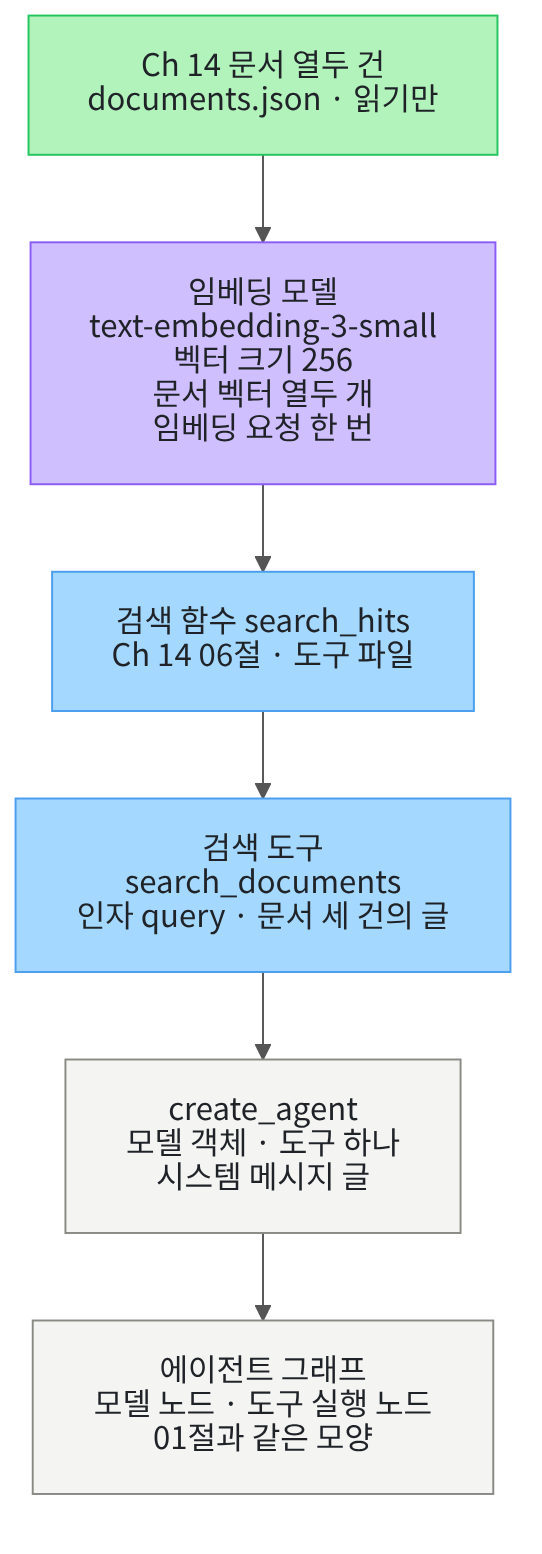

## 1. 준비

01~04절의 에이전트 그래프는 노트북 안 규정 딕셔너리를 찾는 도구를 썼습니다.
이 절에서는 Ch 14에서 쓴 문서 열두 건과 검색 함수를 가져와, 그 검색을 도구로 바꿉니다.
제목의 retriever는 질문을 받아 가까운 문서를 찾아 주는 검색 부분을 가리키는 영어 말입니다.
이 노트북에서는 Ch 14 06절 검색 함수 `search_hits`가 그 일을 합니다.

첫 셀은 패키지 여섯 개를 설치하고 설치된 판 번호를 출력합니다.
01~04절처럼 numpy도 함께 설치합니다.
이 절부터는 도구 파일의 거리 계산 함수가 NumPy로 벡터를 계산합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "langgraph==1.2.11" "numpy==2.5.3" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("numpy:", version("numpy"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langgraph: 1.2.11
numpy: 2.5.3
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `langgraph: 1.2.11`·`numpy: 2.5.3`·`python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
임베딩 모델 `OpenAIEmbeddings`는 Ch 9 01절에서 처음 썼습니다.
함수 `convert_to_openai_tool`은 Ch 19 01절에서 도구 명세를 볼 때 썼습니다.
모듈 `json`과 `os`는 Ch 14에서 문서 파일을 읽고 폴더를 찾을 때 썼습니다.

In [2]:
# 문서 파일을 읽을 이름, 임베딩 모델, 에이전트와 도구를 만드는 이름을 가져옵니다
import json
import os

from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import tool
from langchain_core.utils.function_calling import convert_to_openai_tool
from langchain_openai import OpenAIEmbeddings

# 앞에서 배운 함수는 도구 파일에서 가져옵니다(search_hits·print_ranked는 이 절부터 가져옵니다)
from runner_tools import agent_row, estimate_cost, print_branches, print_ranked
from runner_tools import search_hits, show_messages, sum_usage

print("이 챕터에서 처음 가져온 이름:", "OpenAIEmbeddings", "search_hits", "print_ranked")

이 챕터에서 처음 가져온 이름: OpenAIEmbeddings search_hits print_ranked


**결과 읽기** — 출력 줄 `이 챕터에서 처음 가져온 이름: OpenAIEmbeddings search_hits print_ranked`가 보입니다.
Ch 9~14에서 쓴 이름이지만, 이 챕터에서는 처음 가져옵니다.

앞에서 배운 함수는 `runner_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

함수 `search_hits`는 Ch 14 06절, `print_ranked`는 Ch 12 05절에서 배웠습니다.
함수 `search_hits`가 안에서 부르는 `rank_by_distance`·`cosine_distance`·`cosine_similarity`도 함께 옮겼습니다.
다섯 함수 모두 Ch 14 도구 파일에서 본문을 글자 그대로 옮겼고, 인자 모양도 Ch 14와 같습니다.
거리 계산은 Ch 5 02절처럼 NumPy로 합니다.
나머지 다섯 이름은 01~03절에서 이 도구 파일로 옮긴 함수입니다.

## 2. 키와 모델 준비

모델은 01절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.
이렇게 만든 모델 객체를 이 절의 에이전트 그래프에 넘깁니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 쓰는 답 글과 검색어가 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-25에 이 모델로 실행한 결과입니다.

## 3. Ch 14 문서와 질문

05절부터는 Ch 14 실습 폴더의 문서 모음을 씁니다.
Ch 14에서 검색에 쓴 문서 열두 건과 질문 여덟 건입니다.
두 파일이 Ch 14 폴더에 있으므로, 다음 셀은 먼저 프로젝트 맨 위 폴더를 찾습니다.
다음 셀은 Ch 14 06절 셀과 글자까지 같은 코드입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력은 실행 도구에 도구 파일 폴더를 따로 알려 준 실행이라 `.`이 찍혔습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.

다음 셀은 두 파일을 읽습니다.
코드 줄은 Ch 14 06절과 같고, 첫 줄 주석만 이 절에 맞게 고쳤습니다.

In [6]:
# Ch 14 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`로, Ch 14와 같은 자료입니다.
두 파일은 Ch 14 실습 폴더의 파일이라, 이 노트북은 읽기만 합니다.

다음 셀은 Ch 14처럼 문서마다 제목과 본문을 빈칸 하나로 이어 붙입니다.
문서 ID로 그 글을 찾는 딕셔너리 `text_by_doc`도 함께 만듭니다.
5절 검색 도구가 찾은 문서의 글을 이 딕셔너리에서 꺼냅니다.

In [7]:
# 문서 12건의 제목과 본문을 이어 붙이고, 문서 ID 목록과 문서 ID로 글을 찾는 딕셔너리를 만듭니다
doc_texts = []
doc_ids = []
text_by_doc = {}
for doc in docs:
    # Ch 12·14와 같은 「제목 + 빈칸 + 본문」 모양입니다
    doc_text = doc["title"] + " " + doc["text"]
    doc_texts.append(doc_text)
    doc_ids.append(doc["doc_id"])
    text_by_doc[doc["doc_id"]] = doc_text
print("문서 ID 목록:")
print(doc_ids)

문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


**결과 읽기** — 라벨 줄 `문서 ID 목록:` 아래에 `LIB-001`부터 `ACC-004`까지 열두 개가 보입니다.
Ch 14 06절 출력과 같은 차례입니다.

다음 셀은 질문 파일에서 `C05` 질문을 고릅니다.
질문마다 적힌 정답 문서 ID(Ch 11 01절 말)도 함께 꺼내, 그 문서의 글을 봅니다.

In [8]:
# 질문 파일에서 C05 질문과 그 정답 문서 ID를 고르고, 정답 문서의 글을 봅니다
c05_question = ""
gold_doc_id = ""
for query in queries:
    if query["qid"] == "C05":
        c05_question = query["question"]
        gold_doc_id = query["gold_doc_id"]
print("질문:", c05_question)
print("정답 문서 ID:", gold_doc_id)
print("정답 문서의 글:", text_by_doc[gold_doc_id])

질문: 토요일 자료실 폐관 시각은?
정답 문서 ID: FAC-003
정답 문서의 글: 운영 시간 평일 자료실은 오전 9시부터 오후 9시까지 운영합니다. 토요일은 오후 5시에 문을 닫습니다.


**결과 읽기** — 출력 줄 `질문: 토요일 자료실 폐관 시각은?`과 `정답 문서 ID: FAC-003`입니다.
출력 줄 `정답 문서의 글:` 뒤에 운영 시간 문서의 글이 보입니다.
이 문서는 평일 자료실을 오전 9시부터 오후 9시까지 연다고 적습니다.

01절 규정 딕셔너리는 평일 운영을 09:00~20:00으로 적었습니다.
두 글은 서로 다른 자료라, 이 절은 01절 딕셔너리를 쓰지 않고 고치지도 않습니다.
토요일에 닫는 시각은 두 자료 모두 오후 5시(17:00)입니다.

## 4. 문서 벡터와 검색 함수

다음 셀은 Ch 14 06절과 같은 임베딩 모델과 벡터 크기로 문서 열두 건을 벡터로 바꿉니다.
벡터 크기 인자 `dimensions`는 Ch 10 07절에서 배웠습니다.
메서드 `embed_documents`는 글 목록을 받아 벡터 목록을 내놓고, 이 셀의 임베딩 요청은 1번입니다.
Ch 14 폴더에는 저장해 둔 문서 벡터 파일이 없어, 이 노트북에서 만들고 파일로 쓰지 않습니다.

In [9]:
# Ch 14 06절과 같은 임베딩 모델과 벡터 크기로 문서 12건을 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`과 `벡터의 숫자 개수 설정: 256`입니다.
출력 줄 `문서 벡터 수: 12`로, 문서마다 벡터가 하나씩 생겼습니다.
설정 둘은 Ch 14 06절 출력과 같습니다.

다음 셀은 Ch 14 06절처럼 질문 글을 그대로 검색 함수에 넣습니다.
함수 `search_hits`는 질문 글을 벡터로 바꾸고, 거리가 작은 차례로 문서 `top_count`건을 내놓습니다.
부를 때마다 임베딩 요청이 1번 나갑니다.
자를 개수 `top_count`는 Ch 14에서 나란히 볼 때 쓴 3으로 둡니다.

In [10]:
# Ch 14처럼 질문 글을 그대로 검색 함수에 넣어, 거리가 가까운 문서 세 건을 봅니다(임베딩 요청 1번)
top_count = 3
question_hits = search_hits(embedding_model, c05_question, doc_vectors, doc_ids, top_count)
print("질문 글을 그대로 검색한 순위:")
print_ranked(question_hits, "거리")

질문 글을 그대로 검색한 순위:
순위 | 문서 ID | 거리
1 | FAC-003 | 0.6
2 | LIB-002 | 0.67
3 | FAC-004 | 0.72


**결과 읽기** — 라벨 줄 `질문 글을 그대로 검색한 순위:` 아래 표의 첫 줄이 `1 | FAC-003 | 0.6`입니다.
정답 문서 `FAC-003`이 첫 자리에 왔고, 둘째 자리는 `LIB-002`입니다.
거리는 작을수록 가깝고, Ch 12 01절처럼 소수 둘째 자리까지 남긴 값입니다.

임베딩 값은 요청마다 아주 조금 달라질 수 있어, 거리의 끝자리가 바뀔 수 있습니다.
이번 실행에서는 셋째 자리가 `FAC-004`, 거리는 `0.72`였습니다.

## 5. 검색 함수를 도구로 감싸기

검색 함수를 도구로 감싸면, 모델이 도구 호출 요청으로 검색을 부를 수 있습니다.
도구의 매개변수 `query`에는 모델이 적은 검색어가 들어옵니다.
도구 몸통은 그 검색어로 `search_hits`를 부르고, 찾은 문서마다 문서 ID와 글을 한 줄씩 잇습니다.
이어 붙인 글이 도구 메시지가 되어, 다음 모델 요청에 실립니다.

도구 안에서 쓰는 `doc_vectors`·`doc_ids`·`text_by_doc`는 이 노트북에서 만든 이름입니다.
01절 도구가 딕셔너리 `POLICIES`를 읽은 것과 같은 모양입니다.
도구 메시지에는 거리를 넣지 않고, 문서 ID와 글만 적습니다.

In [11]:
# 검색 함수 search_hits를 도구로 감쌉니다(맨 @tool 줄 — Ch 19 01절, 부를 때마다 임베딩 요청 1번)
@tool
def search_documents(query: str):
    """교육센터 자료실 안내 문서 열두 건에서 검색어와 가까운 문서 세 건을 찾습니다. query에는 찾을 내용을 짧은 검색어로 넣습니다."""
    hit_list = search_hits(embedding_model, query, doc_vectors, doc_ids, top_count)
    # 문서마다 [문서 ID]와 글을 한 줄로 이어, 도구 메시지가 될 글을 만듭니다(Ch 14 01절 자료 줄과 같은 모양)
    found_text = ""
    for hit in hit_list:
        doc_id = hit["doc_id"]
        found_text = found_text + "[" + doc_id + "] " + text_by_doc[doc_id] + "\n"
    return found_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 이름은 함수 이름 `search_documents`이고, 모델이 읽는 설명 글은 독스트링입니다.
이 도구를 부를 때마다 몸통의 `search_hits`가 임베딩 요청을 1번 보냅니다.

다음 셀은 Ch 19 01절처럼 도구 이름과 입력 형식, 도구 명세의 인자를 봅니다.

In [12]:
# 도구 이름, 모델이 채울 인자(입력 형식), 모델 요청에 실릴 도구 명세의 인자를 봅니다(Ch 19 01절)
arg_names = list(search_documents.args.keys())
tool_spec = convert_to_openai_tool(search_documents)
spec_args = tool_spec["function"]["parameters"]["properties"]
spec_names = list(spec_args.keys())
print("도구 이름:", search_documents.name)
print("입력 형식의 인자:", arg_names)
print("명세의 인자:", spec_names)

도구 이름: search_documents
입력 형식의 인자: ['query']
명세의 인자: ['query']


**결과 읽기** — 출력 줄 `도구 이름: search_documents`와 `입력 형식의 인자: ['query']`입니다.
출력 줄 `명세의 인자: ['query']`로, 모델에게 보이는 인자는 `query` 하나입니다.
모델이 채울 값은 검색어뿐이고, 문서 벡터와 자를 개수는 노트북이 정해 둔 값입니다.

## 6. 검색 도구를 넣은 에이전트 그래프

시스템 메시지 글의 첫 문장은 01절 4절 글과 같습니다.
둘째 문장은 도구 이름과 근거를 이 절 도구에 맞게 고쳤습니다.
셋째 문장은 찾은 문서에 답이 없을 때 검색어를 바꿔 한 번만 더 검색하라는 규칙입니다.
이 규칙은 모델에게 적은 글이고, 검색 횟수를 세거나 막는 코드는 없습니다.

다음 셀은 01절처럼 모델 객체·도구 목록·시스템 메시지 글을 넘겨 에이전트 그래프를 만듭니다.

In [13]:
# 모델 객체·검색 도구·시스템 메시지 글을 넘겨 에이전트 그래프를 만듭니다(요청은 아직 보내지 않음)
system_text = "교육센터 자료실 안내 도우미입니다. 자료실 이용을 묻는 질문에는 search_documents 도구로 찾은 문서 글에 근거해 답하세요. 찾은 문서에 답이 없으면 검색어를 바꿔 한 번만 더 검색하고, 그래도 없으면 문서에서 찾지 못했다고 답하세요."
agent = create_agent(model, tools=[search_documents], system_prompt=system_text)
print("만든 것의 종류:", type(agent).__name__)

만든 것의 종류: CompiledStateGraph


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`로, 01절과 같은 종류의 그래프입니다.
이 줄에서는 모델 요청도 임베딩 요청도 나가지 않습니다.

다음 셀은 02절 함수 `print_branches`로 노드와 조건 함수를 봅니다.

In [14]:
# 검색 도구를 넣은 에이전트 그래프의 노드와 조건 함수를 봅니다(02절 함수 print_branches — 도구 파일)
print("등록된 노드:", list(agent.builder.nodes))
print_branches(agent)

등록된 노드: ['model', 'tools']
tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model']
model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__']


**결과 읽기** — 출력 줄 `등록된 노드: ['model', 'tools']`는 01절과 같습니다.
출력 줄 `tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model']`도 01절과 같습니다.
출력 줄 `model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__']`도 01절과 같습니다.
도구를 검색 도구로 바꿔도 에이전트 그래프의 모양은 바뀌지 않았습니다.

## 7. C05 질문 보내기

실행 전에 예상해 봅니다.
모델이 검색 도구를 한 번 부르고, 도구 메시지 첫 줄에 정답 문서 `FAC-003`이 올 것입니다.
그러면 모델 요청은 2번, 도구 안 임베딩 요청은 1번입니다.
메시지 칸에는 메시지 넷이 남을 것입니다.

In [15]:
# C05 질문을 에이전트 그래프에 보냅니다(모델 노드마다 모델 요청 1번, 검색 도구마다 임베딩 요청 1번)
c05_state = {"messages": [HumanMessage(content=c05_question)]}
c05_result = agent.invoke(c05_state)
print("메시지 칸의 메시지 수:", len(c05_result["messages"]))
print("메시지 칸:")
show_messages(c05_result["messages"])

메시지 칸의 메시지 수: 4
메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['search_documents']
ToolMessage | 결과 상태: success | 내용: [FAC-003] 운영 시간 평일 자료실은 오전 9시부터 오후 9시까지 운영합니다. 토요일은 오후 5시에 문을 닫습니다.
[LIB-002] 연체와 대출 제한 반납 예정일을 넘기면 연체한 날짜만큼 새 대출이 제한됩니다. 연체료는 부과하지 않습니다.
[ACC-004] 졸업생 회원 졸업생은 동문 회원으로 전환한 뒤 자료실을 이용할 수 있습니다. 대출 권수는 두 권입니다.

AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `메시지 칸의 메시지 수: 4`입니다.
라벨 줄 `메시지 칸:` 아래 둘째 줄 `AIMessage | 도구 호출 요청: ['search_documents']`에서 검색 도구를 불렀습니다.
셋째 줄 도구 메시지의 내용은 문서 세 줄이고, 첫 줄이 `[FAC-003]`으로 시작합니다.
마지막 줄 `AIMessage | 도구 호출 요청: []`에서 요청이 없어 흐름이 끝났습니다.

다음 셀은 첫 응답에서 모델이 도구 호출 요청에 채운 인자를 봅니다.

In [16]:
# 둘째 메시지(첫 응답)에 담긴 검색 도구 호출 요청의 이름과, 모델이 채운 인자(검색어)를 봅니다
c05_first = c05_result["messages"][1]
for call in c05_first.tool_calls:
    print("도구 이름:", call["name"], "| 인자:", call["args"])

도구 이름: search_documents | 인자: {'query': '토요일 자료실 폐관 시각'}


**결과 읽기** — 출력 줄은 `도구 이름: search_documents | 인자:`로 시작합니다.
인자 딕셔너리의 키는 `query` 하나입니다.
Ch 14 06절에서는 코드가 질문 글을 그대로 검색에 넣었습니다.
이 흐름에서는 검색에 넣을 글을 모델이 인자로 적습니다.

검색어는 모델이 쓴 글이라 실행마다 달라질 수 있습니다.
이번 실행에서는 `{'query': '토요일 자료실 폐관 시각'}`으로, 질문 글 끝의 「은?」만 뺀 글이었습니다.
그래서 도구 메시지 셋째 줄이 4절 순위의 셋째 자리와 달랐습니다.

같은 검색어로 검색하면 같은 문서가 나오는지 봅니다.
다음 셀은 첫 응답의 도구 호출 요청을 Ch 19 05절처럼 도구에 그대로 다시 보냅니다.
도구 호출 요청을 통째로 넘기면 도구 메시지가 나오고, 임베딩 요청이 1번 더 나갑니다.

In [17]:
# 첫 응답의 도구 호출 요청을 도구에 그대로 다시 보내, 같은 검색어면 같은 글이 나오는지 봅니다(임베딩 요청 1번)
first_call = c05_first.tool_calls[0]
again_message = search_documents.invoke(first_call)
c05_tool_message = c05_result["messages"][2]
print("다시 받은 메시지의 종류:", type(again_message).__name__)
print("도구 메시지 글과 같은가:", again_message.content == c05_tool_message.content)

다시 받은 메시지의 종류: ToolMessage
도구 메시지 글과 같은가: True


**결과 읽기** — 출력 줄 `다시 받은 메시지의 종류: ToolMessage`입니다.
출력 줄 `도구 메시지 글과 같은가: True`로, 같은 검색어가 같은 문서 셋을 같은 차례로 내놓았습니다.
검색어가 같으면 거리 순위는 검색 함수의 계산으로 정해집니다.

이 비교에는 `assert`를 걸지 않았습니다.
임베딩 값이 요청마다 아주 조금 달라질 수 있어, 거리가 거의 같은 두 문서는 차례가 바뀔 수 있기 때문입니다.

다음 셀은 메시지 칸의 마지막 응답을 봅니다.

In [18]:
# 메시지 칸의 마지막 응답을 봅니다(도구 호출 요청 수와 답 글)
c05_last = c05_result["messages"][-1]
print("마지막 응답의 도구 호출 요청 수:", len(c05_last.tool_calls))
print("답 글:")
print(c05_last.content)

마지막 응답의 도구 호출 요청 수: 0
답 글:
토요일 자료실은 **오후 5시**에 폐관합니다.


**결과 읽기** — 출력 줄 `마지막 응답의 도구 호출 요청 수: 0`입니다.
라벨 줄 `답 글:` 아래가 모델이 도구 메시지를 보고 쓴 답입니다.

답 글은 모델이 쓴 글이라 실행마다 글자가 달라질 수 있습니다.
이번 실행에서는 토요일 폐관 시각을 오후 5시로 답했고, 문서 `FAC-003`의 글과 같은 시각입니다.

## 8. 값 바꿔 보기 · 문서에 없는 질문

바꿀 값은 질문 하나이고, 에이전트 그래프와 시스템 메시지 글은 그대로 둡니다.
문서 열두 건에 주차 이야기가 없는 질문으로 바꿉니다.
실행 전에 예상해 봅니다.
검색 도구는 관련 문서가 없어도 거리가 가까운 문서 세 건을 내놓을 것입니다.
모델이 규칙대로 한 번 더 검색하면, 모델 요청은 3번이고 도구 메시지는 둘일 것입니다.

In [19]:
# 바꿀 값: 질문 하나만, 문서 12건에 답이 없는 질문으로 바꿔 같은 에이전트 그래프에 보냅니다
parking_question = "자료실 주차 요금은 얼마인가요?"
parking_state = {"messages": [HumanMessage(content=parking_question)]}
parking_result = agent.invoke(parking_state)
print("메시지 칸의 메시지 수:", len(parking_result["messages"]))
print("메시지 칸:")
show_messages(parking_result["messages"])

메시지 칸의 메시지 수: 6
메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['search_documents']
ToolMessage | 결과 상태: success | 내용: [FAC-002] 프린터 이용 흑백 인쇄는 장당 50원이고 컬러 인쇄는 장당 300원입니다. 결제는 학생증 잔액을 사용합니다.
[ACC-004] 졸업생 회원 졸업생은 동문 회원으로 전환한 뒤 자료실을 이용할 수 있습니다. 대출 권수는 두 권입니다.
[ACC-001] 비밀번호 재설정 비밀번호를 잊으면 등록한 이메일로 재설정 링크를 받습니다. 링크는 30분 동안 유효합니다.

AIMessage | 도구 호출 요청: ['search_documents']
ToolMessage | 결과 상태: success | 내용: [FAC-004] 분실물 보관 분실물은 안내 데스크에서 30일 동안 보관합니다. 신분증으로 본인 확인 후 수령합니다.
[ACC-004] 졸업생 회원 졸업생은 동문 회원으로 전환한 뒤 자료실을 이용할 수 있습니다. 대출 권수는 두 권입니다.
[FAC-002] 프린터 이용 흑백 인쇄는 장당 50원이고 컬러 인쇄는 장당 300원입니다. 결제는 학생증 잔액을 사용합니다.

AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `메시지 칸의 메시지 수: 6`입니다.
라벨 줄 `메시지 칸:` 아래에 `AIMessage | 도구 호출 요청: ['search_documents']`가 두 번 보입니다.
도구 메시지도 둘이고, 두 도구 메시지 모두 문서 세 줄을 담았습니다.
첫 도구 메시지의 첫 줄은 `[FAC-002]`로, 주차가 아니라 프린터 이용 요금 문서입니다.
검색 함수는 거리가 가까운 차례로 늘 `top_count`건을 내놓으므로, 관련 문서가 없어도 문서가 나옵니다.

다음 셀은 응답마다 도구 호출 요청 수와 검색어를 봅니다.

In [20]:
# 응답마다 검색 도구 호출 요청 수와, 모델이 채운 인자(검색어)를 차례로 봅니다
for message in parking_result["messages"]:
    if type(message).__name__ == "AIMessage":
        print("응답 | 도구 호출 요청 수:", len(message.tool_calls))
        for call in message.tool_calls:
            print("  인자:", call["args"])

응답 | 도구 호출 요청 수: 1
  인자: {'query': '주차 요금'}
응답 | 도구 호출 요청 수: 1
  인자: {'query': '주차'}
응답 | 도구 호출 요청 수: 0


**결과 읽기** — 라벨이 `응답 | 도구 호출 요청 수:`인 줄이 셋이고, 값은 차례로 `1`·`1`·`0`입니다.
응답마다 검색 요청을 하나씩 보내, 검색을 두 응답에 걸쳐 두 번 했습니다.
시스템 메시지 글의 「한 번만 더 검색」대로, 다시 검색은 한 번이었습니다.
그래프에는 검색 횟수를 세거나 막는 줄이 없고, 세 번째 검색을 고른 실행은 이번에 없었습니다.

검색어는 실행마다 달라질 수 있습니다.
이번 실행에서는 첫 검색어가 `{'query': '주차 요금'}`, 둘째가 `{'query': '주차'}`였습니다.

다음 셀은 바꾼 질문의 마지막 응답을 봅니다.

In [21]:
# 바꾼 질문의 마지막 응답을 봅니다(도구 호출 요청 수와 답 글)
parking_last = parking_result["messages"][-1]
print("마지막 응답의 도구 호출 요청 수:", len(parking_last.tool_calls))
print("답 글:")
print(parking_last.content)

마지막 응답의 도구 호출 요청 수: 0
답 글:
자료실 주차 요금에 대한 내용은 문서에서 찾지 못했습니다.


**결과 읽기** — 출력 줄 `마지막 응답의 도구 호출 요청 수: 0`입니다.
라벨 줄 `답 글:` 아래가 모델이 도구 메시지 둘을 보고 쓴 답입니다.

답 글은 실행마다 글자가 달라질 수 있습니다.
이번 실행에서는 문서에서 주차 요금을 찾지 못했다는 뜻의 한 문장이었습니다.

## 9. 요청 수와 예상 비용

다음 셀은 두 결과의 도구 메시지마다 문서 ID를 꺼내 셉니다.
도구 몸통은 줄 머리에 대괄호로 문서 ID를 적으므로, 대괄호로 시작하는 줄이 문서 한 건입니다.
메서드 `split`으로 줄을 나누고, `]` 앞 글자에서 첫 글자를 빼면 문서 ID가 남습니다.

In [22]:
# 두 결과의 도구 메시지마다, [로 시작하는 줄에서 문서 ID를 꺼내 셉니다
for result in [c05_result, parking_result]:
    for message in result["messages"]:
        if type(message).__name__ == "ToolMessage":
            found_ids = []
            for line in message.content.split("\n"):
                if line.startswith("["):
                    found_ids.append(line.split("]")[0][1:])
            print("도구 메시지의 문서 ID:", found_ids)
            # 줄 수는 도구 몸통이 top_count로 정하는 값이라, 모델이 무엇을 검색해도 같아야 합니다
            assert len(found_ids) == top_count, "도구 메시지마다 문서 줄이 top_count개여야 합니다"

도구 메시지의 문서 ID: ['FAC-003', 'LIB-002', 'ACC-004']
도구 메시지의 문서 ID: ['FAC-002', 'ACC-004', 'ACC-001']
도구 메시지의 문서 ID: ['FAC-004', 'ACC-004', 'FAC-002']


**결과 읽기** — 라벨이 `도구 메시지의 문서 ID:`인 줄이 셋입니다.
첫 줄 `['FAC-003', 'LIB-002', 'ACC-004']`는 7절, 둘째·셋째 줄은 8절의 도구 메시지입니다.
세 줄 모두 문서 ID가 셋이고, 셀의 `assert`는 이 개수에만 걸었습니다.
개수는 도구 몸통이 `top_count`로 정하는 값이라, 모델이 무엇을 검색해도 같습니다.

8절 두 도구 메시지는 이번 실행에서 `['FAC-002', 'ACC-004', 'ACC-001']`과 `['FAC-004', 'ACC-004', 'FAC-002']`였습니다.
검색어가 달라지면 이 차례도 달라질 수 있습니다.

다음 셀은 01절 10절 함수 `agent_row`로 두 질문을 한 줄씩 적습니다.

In [23]:
# 두 질문의 기록을 한 줄씩 적어 출력합니다(01절 10절 함수 agent_row — 도구 파일)
run_rows = []
run_rows.append(agent_row("C05 질문", c05_result))
run_rows.append(agent_row("주차 질문", parking_result))
print("질문 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝")
for row in run_rows:
    print(row["질문"], "|", row["모델 요청 수"], "|", row["도구 메시지 수"], "|", row["호출 ID 짝"])
    # 도구 메시지마다 요청 id를 옮겨 적는 것은 코드가 하는 일이라, 짝은 매번 맞아야 합니다
    assert row["호출 ID 짝"], "도구 메시지마다 같은 차례의 요청 id가 옮겨져야 합니다"

질문 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝
C05 질문 | 2 | 1 | True
주차 질문 | 3 | 2 | True


**결과 읽기** — 라벨 줄 아래 두 줄이 `C05 질문 | 2 | 1 | True`와 `주차 질문 | 3 | 2 | True`입니다.
두 질문 모두 모델 요청 수가 도구 메시지 수보다 1 많았습니다.
01절에서 본 것처럼, 이 셈은 응답마다 요청을 하나씩 받을 때만 맞습니다.
호출 ID 짝은 두 질문 모두 맞았고, 셀의 `assert`로 확인했습니다.

검색 도구는 부를 때마다 임베딩 요청을 1번 보냅니다.
그래서 도구 메시지 수가 곧 도구 안 임베딩 요청 수입니다.
다음 셀은 이 노트북이 보낸 임베딩 요청을 셉니다.
검색 함수를 직접 부른 곳은 4절 질문 글 검색과 7절 다시 부르기, 두 곳입니다.

In [24]:
# 이 노트북이 보낸 임베딩 요청을 셉니다(도구 메시지 하나 = 도구 안 검색 한 번 = 임베딩 요청 1번)
doc_requests = 1
direct_requests = 2
tool_requests = run_rows[0]["도구 메시지 수"] + run_rows[1]["도구 메시지 수"]
embed_total = doc_requests + direct_requests + tool_requests
print("문서 벡터를 만든 요청:", doc_requests)
print("검색 함수를 직접 부른 요청(4절·7절):", direct_requests)
print("검색 도구 안에서 보낸 요청:", tool_requests)
print("임베딩 요청 합계:", embed_total)

문서 벡터를 만든 요청: 1
검색 함수를 직접 부른 요청(4절·7절): 2
검색 도구 안에서 보낸 요청: 3
임베딩 요청 합계: 6


**결과 읽기** — 출력 줄 `검색 도구 안에서 보낸 요청: 3`과 `임베딩 요청 합계: 6`입니다.
문서 벡터를 만든 요청 1번과 직접 부른 요청 2번을 더한 값입니다.
모델이 검색을 더 고르면 도구 안 요청과 합계가 함께 늘어납니다.

다음 셀은 Ch 19 05절 함수 `sum_usage`로 두 결과의 모델 요청 수와 토큰을 더합니다.

In [25]:
# 두 결과의 모델 요청 수와 입력·출력 토큰을 더합니다(Ch 19 05절 함수 sum_usage)
c05_usage = sum_usage(c05_result["messages"])
parking_usage = sum_usage(parking_result["messages"])
print("C05 질문 사용량:", c05_usage)
print("주차 질문 사용량:", parking_usage)

C05 질문 사용량: {'requests': 2, 'input_tokens': 638, 'output_tokens': 44}
주차 질문 사용량: {'requests': 3, 'input_tokens': 1189, 'output_tokens': 59}


**결과 읽기** — `C05 질문 사용량:`은 `'requests': 2`, `주차 질문 사용량:`은 `'requests': 3`입니다.
입력 토큰은 C05 질문 `'input_tokens': 638`, 주차 질문 `'input_tokens': 1189`입니다.
주차 질문은 모델 요청이 한 번 더 있어, 입력 토큰 합이 더 컸습니다.
요청마다 어느 몫이 몇 토큰인지는 나눠 세지 않았습니다.

출력 토큰은 모델이 쓴 글에 따라 실행마다 달라질 수 있습니다.
이번 실행에서는 C05 질문 `'output_tokens': 44`, 주차 질문 `'output_tokens': 59`였습니다.

다음 셀은 Ch 6 06절 함수 `estimate_cost`로 두 사용량의 예상 비용을 셉니다.
요금은 2026-09-17 요금표의 100만 토큰당 달러입니다.

In [26]:
# 2026-09-17 요금표(100만 토큰당 달러)로 두 결과의 모델 몫 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
c05_cost = round(estimate_cost(c05_usage, input_rate, cached_input_rate, output_rate), 6)
parking_cost = round(estimate_cost(parking_usage, input_rate, cached_input_rate, output_rate), 6)
print("C05 질문 예상 비용(달러):", c05_cost)
print("주차 질문 예상 비용(달러):", parking_cost)

C05 질문 예상 비용(달러): 0.000677
주차 질문 예상 비용(달러): 0.001157


**결과 읽기** — 라벨 `C05 질문 예상 비용(달러):`와 `주차 질문 예상 비용(달러):` 뒤 값이 모델 몫의 예상 비용입니다.
요금표로 어림한 값이고, 청구 금액이 아닙니다.
임베딩 요금은 넣지 않았습니다.
이 노트북은 임베딩 요청의 토큰 수를 세지 않기 때문입니다.

출력 토큰이 실행마다 달라질 수 있어, 이 값도 달라질 수 있습니다.
이번 실행에서는 C05 질문 `0.000677`달러, 주차 질문 `0.001157`달러였습니다.

## 정리

1. Ch 14 06절 검색 함수 `search_hits`를 `@tool` 도구로 감싸자, 모델이 인자 `query`에 검색어를 적어 검색을 불렀습니다.
2. 같은 검색어로 도구를 다시 부르면 같은 문서 셋이 같은 차례로 나왔고, 도구 메시지마다 문서는 `top_count`건이었습니다.
3. 문서에 답이 없는 질문에서 모델은 검색을 두 번 했고, 「한 번만 더」는 시스템 메시지 글일 뿐 코드 제한이 아니었습니다.

06절에서는 같은 평가 질문을 두 흐름으로 보내 견줍니다.
검색을 먼저 하는 흐름과, 검색 도구를 쓰는 에이전트 흐름입니다.